In [1]:
import pandas as pd
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from analysis_functions import get_power_data, compute_baseline_stats, detect_power_surges, compute_surge_vs_simpipe_start_endtime_diffs
from analysis_functions import plot_enhanced_visualization

In [24]:
# Data to compare
#data_path = "./data_carbontracker/conf-1/power-run3.xls"                                                                # Tapo Smart plug data measurement
#corresponding_dataset_path = "./data_carbontracker/conf-1/run3.dat"                                                     # Carbontracker/SIMPIPE data

#runNr = 3
runNr = "X"
simpipe_datetime_shift = 60 # minutes to shift data

base_path = "../../data/power-stress-3"
data_path = f"{base_path}/power-run{runNr}.xls"             # Tapo Smart plug data measurement
corresponding_dataset_path = f"{base_path}/run{runNr}.dat"  # Carbontracker/SIMPIPE data

In [25]:
power_data = get_power_data(data_path)                                                                                  # Tapo Smart plug data
carbontracker_simpipe_data = pd.read_csv(corresponding_dataset_path, sep=r'\s+', comment='#', header=0)      # Carbontracker/SIMPIPE data

if simpipe_datetime_shift != 0:
    carbontracker_simpipe_data = carbontracker_simpipe_data.copy()
    # Convert start and stop columns to datetime if they aren't already
    carbontracker_simpipe_data["start"] = pd.to_datetime(carbontracker_simpipe_data["start"])
    carbontracker_simpipe_data["stop"] = pd.to_datetime(carbontracker_simpipe_data["stop"])
    # Now apply the time shift
    carbontracker_simpipe_data["start"] += pd.Timedelta(minutes=simpipe_datetime_shift)
    carbontracker_simpipe_data["stop"] += pd.Timedelta(minutes=simpipe_datetime_shift)

FileNotFoundError: [Errno 2] No such file or directory: '../../data/power-stress-3/runX.dat'

In [26]:
# runNr 1
#min_duration_minutes = 60           # minimum duration (s) for a surge to be considered
#surge_threshold_multiplier = 1.05   # threshold multiplier for surge detection (relative to baseline)

# runNr 2
min_duration_minutes = 60           # minimum duration (s) for a surge to be considered
surge_threshold_multiplier = 1.07   # threshold multiplier for surge detection (relative to baseline)

# runNr 3
#min_duration_minutes = 60           # minimum duration (s) for a surge to be considered
#surge_threshold_multiplier = 1.01   # threshold multiplier for surge detection (relative to baseline)

baseline_stats = compute_baseline_stats(df=power_data, percentile_threshold=70, print_stats=True)
surge_periods, surge_threshold = detect_power_surges(power_data, baseline_stats, min_duration_minutes=min_duration_minutes, surge_threshold_multiplier=surge_threshold_multiplier)

     compute_baseline_stats -- Baseline analysis...
      Power threshold for baseline: 210.0 W
      Baseline periods: 128 out of 172 (74.4%)
      Mean baseline power: 205.0 W
      Median baseline power: 205.0 W
      Std baseline power: 2.9 W
      Power range: 199.0 - 210.0 W
      Mean baseline energy per period: 0.017087 kWh
      Total baseline energy: 2.1872 kWh



Carbontracker period: 2026-10-26 08:32:31 to 2026-10-26 11:32:45
Power data period: 2026-10-25 21:35:00 to 2026-10-26 11:50:00


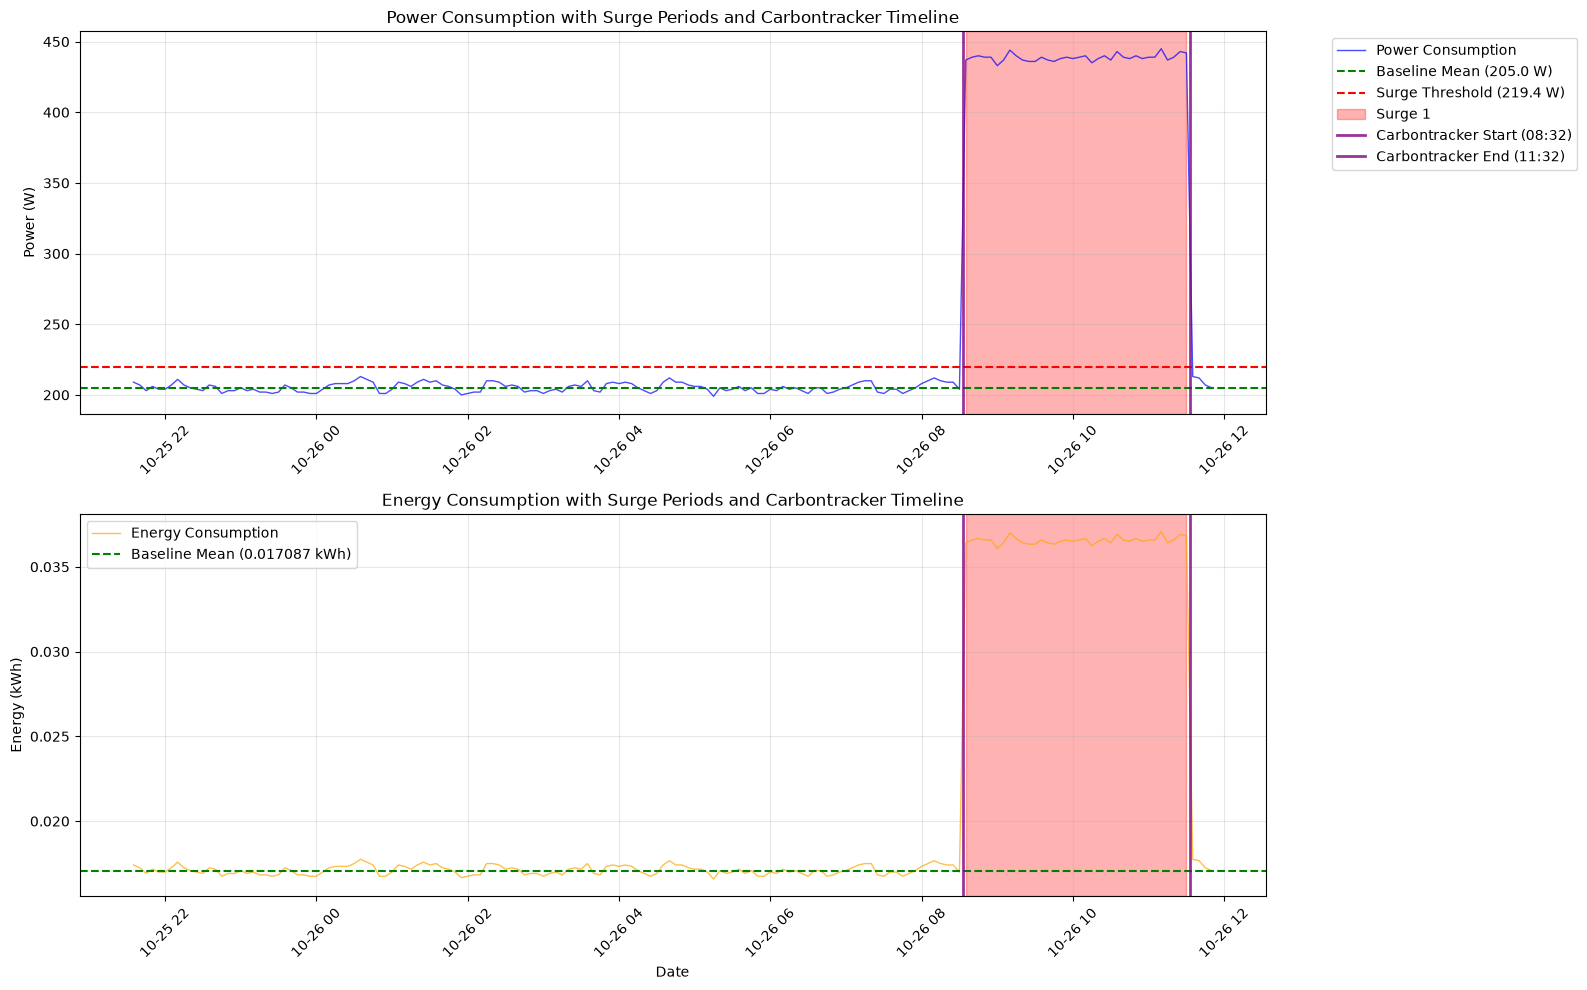

=== CARBONTRACKER vs POWER SURGE ANALYSIS ===
Carbontracker monitoring period: 08:32 - 11:32
Carbontracker duration: 3.00 hours

Overlap analysis with detected surge periods:
  Surge 1: 100.0% overlap (175.0/175.0 minutes)
    Surge: 08:35 - 11:30
    Overlap: 08:35 - 11:30

Power statistics during Carbontracker period:
  Average power: 438.8 W
  Peak power: 445.0 W
  Total energy: 1.3163 kWh
  Carbontracker reported energy: 3.2024 kWh
  Energy difference: 1.8862 kWh


In [27]:
plot_enhanced_visualization(carbontracker_simpipe_data, power_data, baseline_stats, surge_periods, surge_threshold)

In [9]:
compute_surge_vs_simpipe_start_endtime_diffs(carbontracker_simpipe_data=carbontracker_simpipe_data, surge_periods=surge_periods)

=== TIME DIFFERENCE ANALYSIS ===
Carbontracker start time: 2026-10-01 08:50:08
Carbontracker stop time: 2026-10-01 11:50:14
Carbontracker duration: 180.1 minutes

Surge 1:
  Surge start: 2026-10-01 08:55:00
  Surge end: 2026-10-01 11:50:00
  Start time difference from carbontracker start:
    +0.08 hours (4.9 minutes) AFTER carbontracker start
  End time difference from carbontracker stop:
    -0.00 hours (0.2 minutes) BEFORE carbontracker stop

=== TIMING RELATIONSHIPS SUMMARY ===
Surges starting before carbontracker         : 0
Surges overlapping with carbontracker period : 1
Surges starting after carbontracker          : 0

Closest surge to carbontracker start      : Surge 1
Time difference: 4.9 minutes
This surge OVERLAPS with carbontracker execution period


# Analysis of time diffs

...

We therefore compute the differences
* Dstart = diff(simpipe_start - estimated_power_surge_start)
* Dend = diff(simpipe_end - estimated_power_surge_end)
* Delta = (simpipe_start - simpipe_end) - Dend
* Kappa = (simpipe_start - simpipe_end) - Delta

In [11]:
# Data for surge time differences.
# data contains table of surge time differences between Tapo Smart plug and Carbontracker/SIMPIPE for all runs.
# Columns: Configuration, RunNr, Start_Time_Diff_minutes, End_Time_Diff_meconds, SIMPIPE_Duration_minutes
surge_time_diffs = pd.read_csv("../../data/power-stress-2/surge_time_diffs.dat", sep=r'\s+', comment='#', header=0)
# isna
nan_values = surge_time_diffs[surge_time_diffs.isna()["duration"]]
# remove NaN values
surge_time_diffs = surge_time_diffs.dropna()
# compute delta = End_Time_Diff_meconds - Start_Time_Diff_minutes
surge_time_diffs['Delta'] = surge_time_diffs['duration'] - surge_time_diffs['endDiff']
# compute tapo_power_duration
surge_time_diffs['tapo_power_duration'] = surge_time_diffs['startDiff'] - surge_time_diffs['endDiff'] + surge_time_diffs['duration']
# duration diff (diff between estimated power surge in Tapo data and SIMPIPE data)
surge_time_diffs['tapo_simpipe_duration_diff'] = surge_time_diffs['duration'] - surge_time_diffs['tapo_power_duration']

In [12]:
surge_time_diffs

,configuration,runNr,startDiff,endDiff,duration,Delta,tapo_power_duration,tapo_simpipe_duration_diff
0,power-surge,1,0.06,-0.03,180.1,180.13,180.19,-0.09
1,power-surge,2,0.08,-0.01,180.1,180.11,180.19,-0.09
2,power-surge,3,0.06,-0.03,180.1,180.13,180.19,-0.09
3,power-surge,4,0.08,0.00,180.1,180.10,180.18,-0.08


In [13]:
surge_time_diffs.startDiff.mean()
#surge_time_diffs.endDiff.mean()

np.float64(0.07)

In [14]:
# these configurations needs to be rerun:
nan_values

,configuration,runNr,startDiff,endDiff,duration


In [15]:
baseline_stats

{'threshold_power': np.float64(211.0),
 'baseline_periods': 213,
 'total_periods': 287,
 'baseline_percentage': 74.21602787456446,
 'mean_power': np.float64(205.77464788732394),
 'median_power': np.float64(206.0),
 'std_power': np.float64(3.1869301922006605),
 'min_power': np.int64(198),
 'max_power': np.int64(211),
 'mean_energy': np.float64(0.01714788732394366),
 'total_baseline_energy': np.float64(3.6525)}

In [16]:
power_data

,Date,Power(W),Energy(kWh)
1,2026-09-30 14:00:00,205,0.017083
2,2026-09-30 14:05:00,209,0.017417
3,2026-09-30 14:10:00,203,0.016917
4,2026-09-30 14:15:00,203,0.016917
5,2026-09-30 14:20:00,201,0.016750
...,...,...,...
283,2026-10-01 13:30:00,210,0.017500
284,2026-10-01 13:35:00,214,0.017833
285,2026-10-01 13:40:00,213,0.017750
286,2026-10-01 13:45:00,214,0.017833
